In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 160)
OUT = ROOT / "outputs"
def show(name): display(Image(filename=str(OUT / "figures" / f"{name}.png")))


# 07 Walk-forward backtest (saved results)
Timing: signal at close *t*, trade at close *t+1*, new weights earn from *t+2*; 5 bps cost on turnover.

In [2]:
perf = pd.read_csv(OUT / "metrics" / "strategy_performance.csv").set_index("strategy_name")
perf[["ann_return", "ann_vol", "sharpe", "sortino", "max_drawdown", "calmar", "ann_turnover", "ann_cost", "avg_exposure"]].round(3)

,ann_return,ann_vol,sharpe,sortino,max_drawdown,calmar,ann_turnover,ann_cost,avg_exposure
strategy_name,,,,,,,,,
EqualWeight,0.113,0.172,0.565,0.793,-0.527,0.214,0.317,0.000,1.000
MinVariance,0.099,0.143,0.562,0.787,-0.387,0.256,0.637,0.000,1.000
MeanVariance,0.094,0.145,0.526,0.734,-0.392,0.241,1.297,0.001,1.000
VolTarget_HistVol,0.088,0.107,0.613,0.846,-0.241,0.365,1.725,0.001,0.769
VolTarget_GARCH,0.087,0.104,0.622,0.860,-0.253,0.345,1.373,0.001,0.750
VolTarget_RF,0.087,0.109,0.599,0.830,-0.285,0.307,1.241,0.001,0.782
VolTarget_XGB,0.085,0.106,0.586,0.812,-0.281,0.301,1.565,0.001,0.762
VolTarget_Oracle*,0.093,0.101,0.686,0.955,-0.295,0.315,2.351,0.001,0.766
EW_StaticMatched*,0.096,0.135,0.565,0.793,-0.431,0.222,0.247,0.000,0.782


In [3]:
pd.read_csv(OUT / 'tables' / 'gross_vs_net.csv').round(4)

,strategy_name,gross_ann_return,ann_return,gross_sharpe,sharpe,ann_turnover,ann_cost
0,EqualWeight,0.1130,0.1129,0.5655,0.5646,0.3165,0.0002
1,MinVariance,0.0995,0.0991,0.5639,0.5617,0.6365,0.0003
2,MeanVariance,0.0950,0.0943,0.5301,0.5256,1.2967,0.0006
3,VolTarget_HistVol,0.0891,0.0881,0.6211,0.6131,1.7249,0.0009
4,VolTarget_GARCH,0.0879,0.0872,0.6286,0.6221,1.3732,0.0007
5,VolTarget_RF,0.0881,0.0874,0.6050,0.5993,1.2407,0.0006
6,VolTarget_XGB,0.0854,0.0845,0.5931,0.5858,1.5650,0.0008
7,VolTarget_Oracle*,0.0943,0.0930,0.6973,0.6858,2.3508,0.0012
8,EW_StaticMatched*,0.0960,0.0958,0.5655,0.5646,0.2475,0.0001


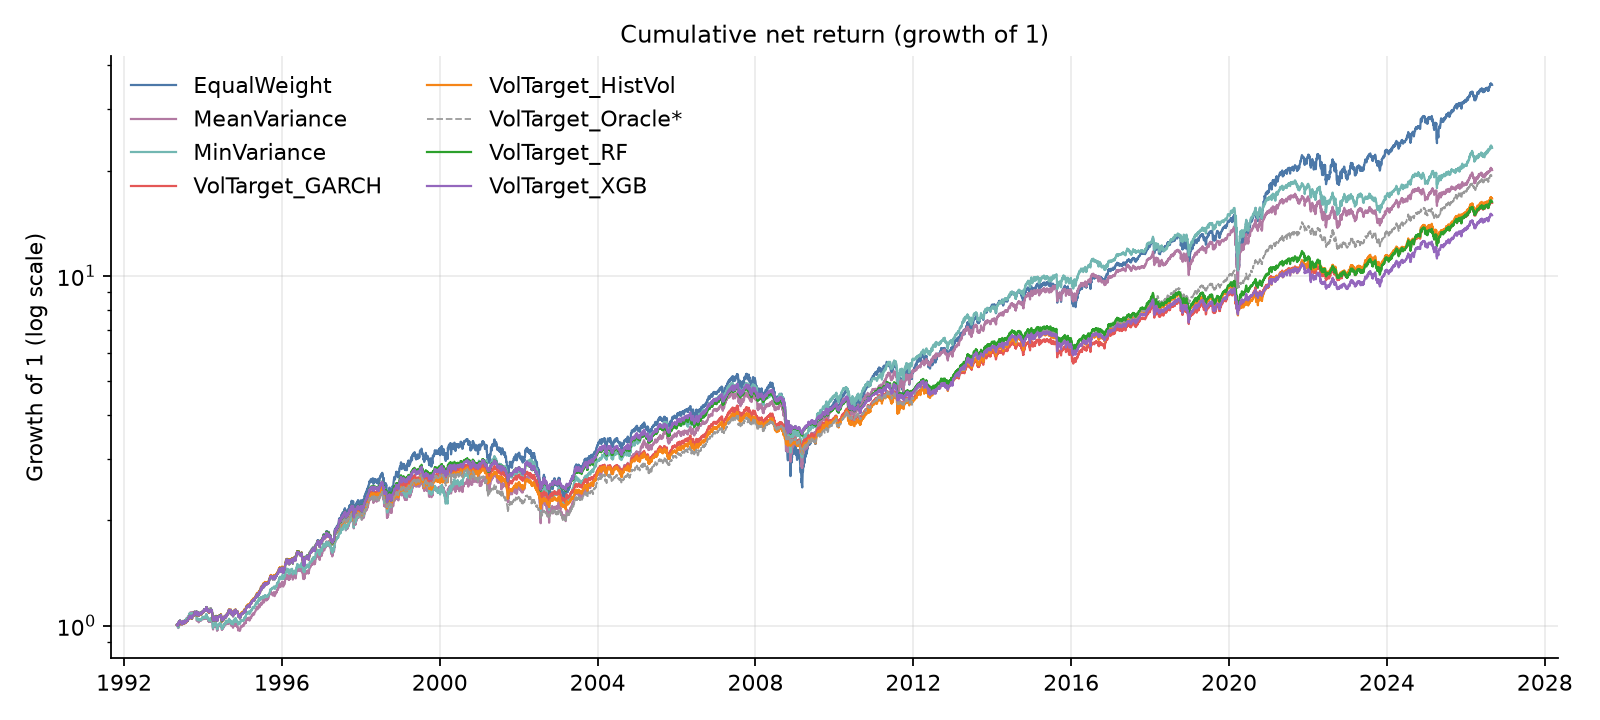

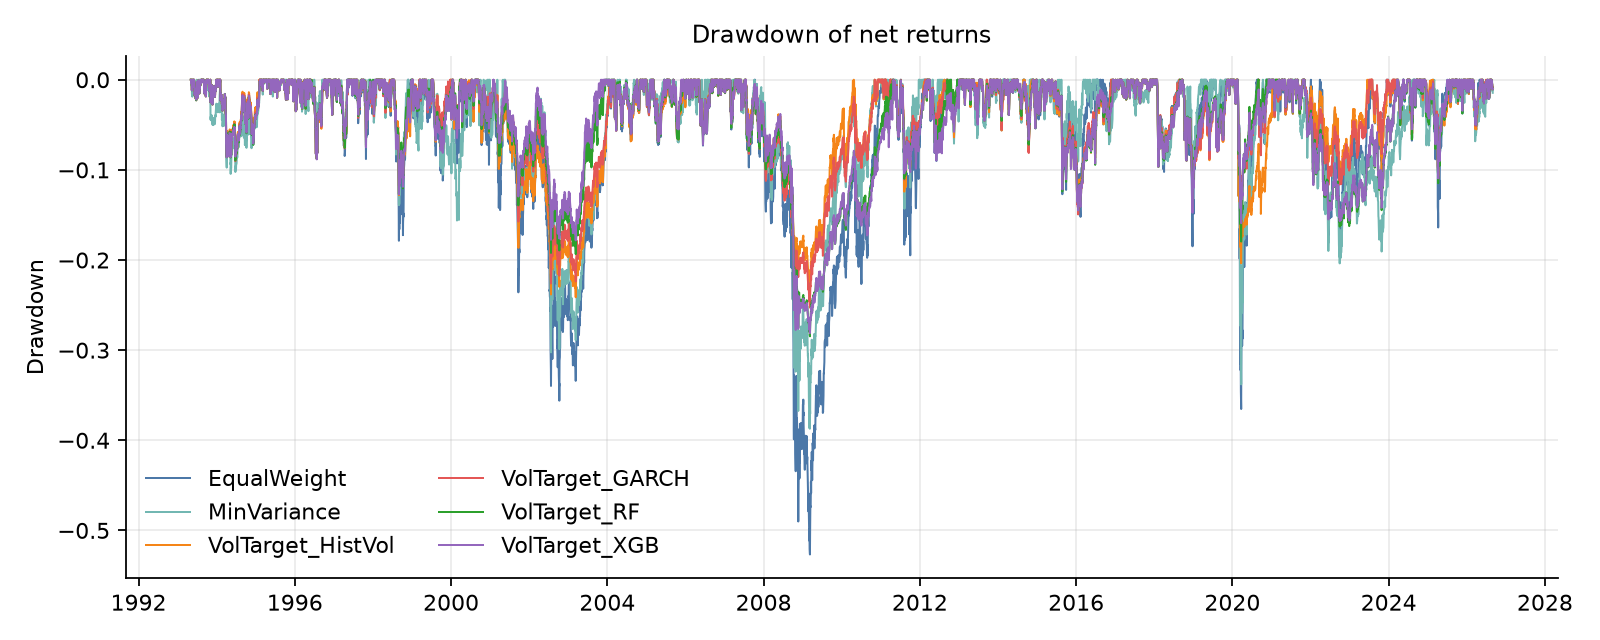

In [4]:
show('fig_cumulative_net_return'); show('fig_drawdowns')

In [5]:
pd.read_csv(OUT / 'tables' / 'sharpe_difference_bootstrap.csv').round(3)

,strategy,benchmark,sharpe_diff,p_value,ci_low,ci_high
0,MinVariance,EqualWeight,-0.003,0.965,-0.135,0.139
1,MeanVariance,EqualWeight,-0.039,0.558,-0.162,0.088
2,VolTarget_HistVol,EqualWeight,0.048,0.505,-0.086,0.177
3,VolTarget_GARCH,EqualWeight,0.057,0.410,-0.077,0.191
4,VolTarget_RF,EqualWeight,0.035,0.555,-0.084,0.149
5,VolTarget_XGB,EqualWeight,0.021,0.730,-0.105,0.139
6,VolTarget_RF,VolTarget_HistVol,-0.014,0.754,-0.107,0.076
7,VolTarget_RF,VolTarget_GARCH,-0.023,0.522,-0.093,0.046
8,VolTarget_RF,EW_StaticMatched*,0.035,0.555,-0.084,0.149
9,VolTarget_XGB,VolTarget_GARCH,-0.036,0.402,-0.124,0.043


In [6]:
w = pd.read_csv(OUT / "portfolios" / "portfolio_weights.csv", parse_dates=["rebalance_date", "execution_date"])
print("min lag between signal and execution (days):", (w.execution_date - w.rebalance_date).dt.days.min())
w.head()

min lag between signal and execution (days): 1


,rebalance_date,execution_date,NoDur,Durbl,Manuf,Enrgy,HiTec,Telcm,Shops,Hlth,Utils,Other,CASH,strategy_name
0,1993-04-30,1993-05-03,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.0,EqualWeight
1,1993-05-28,1993-06-01,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.0,EqualWeight
2,1993-06-30,1993-07-01,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.0,EqualWeight
3,1993-07-30,1993-08-02,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.0,EqualWeight
4,1993-08-31,1993-09-01,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.0,EqualWeight


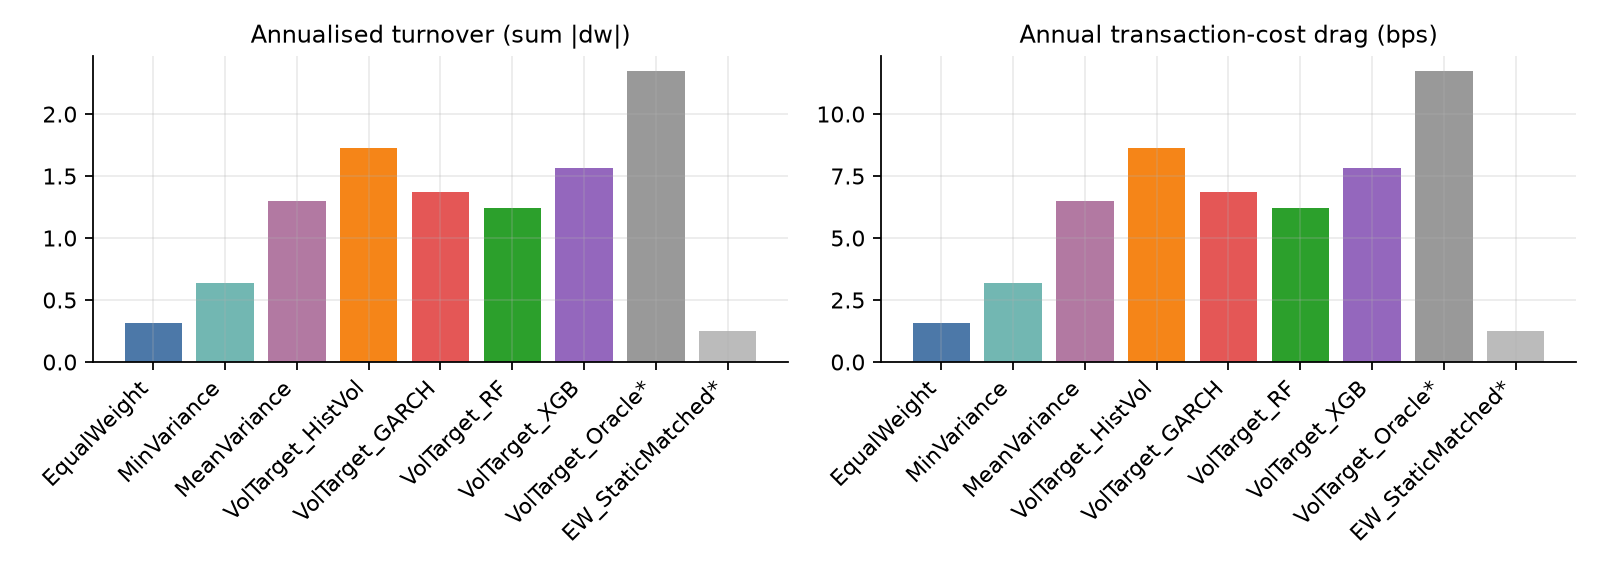

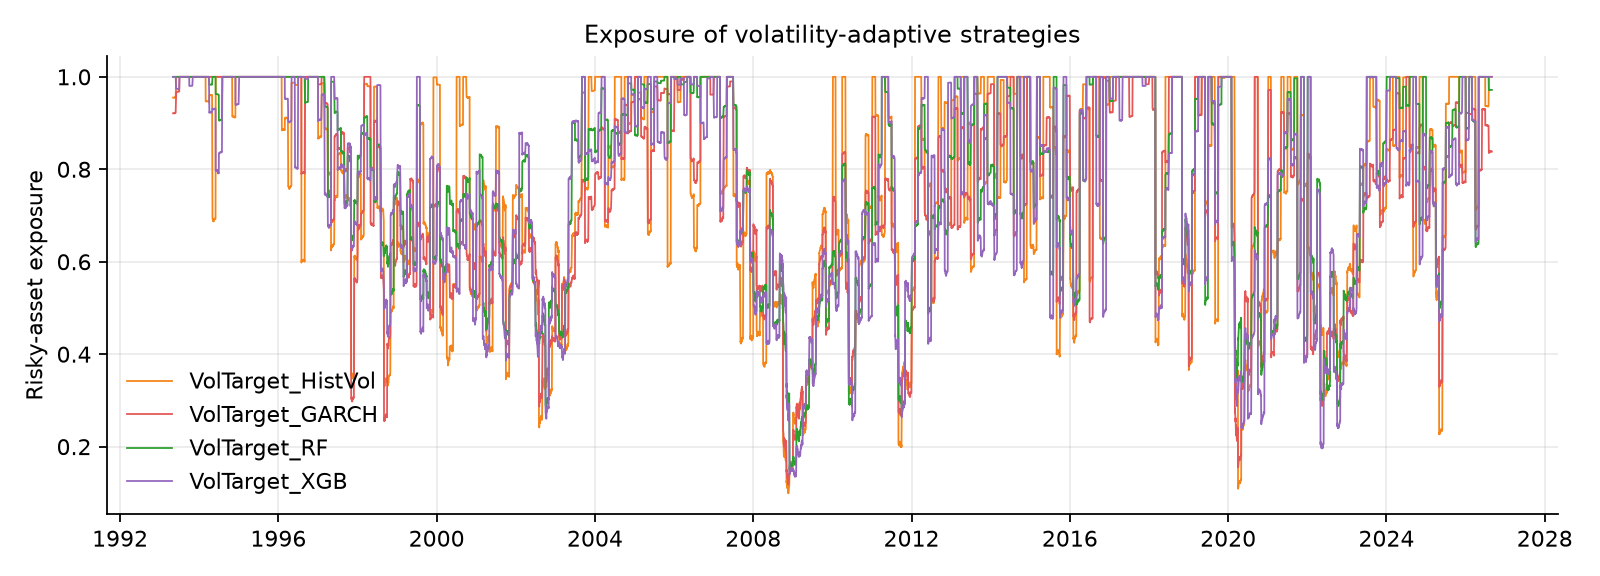

In [7]:
show('fig_turnover_cost'); show('fig_vol_adaptive_exposure')